# Three-layer URL phishing detector
Run `data-cleaning.ipynb` first, then run this notebook top to bottom. The URL model trains up to the configured epoch limit, prints loss and accuracy each epoch, and early-stops when validation loss fails to improve. Whitelist membership and typo similarity are signals to a learned, calibrated probability combiner; neither forces a probability of 0 or 1. A separate decision threshold is selected on held-out validation data to preserve model-only recall. A close match to a protected domain also raises a SUSPICIOUS warning when its calibrated probability falls below the phishing threshold; this warning does not change the probability.

In [93]:
"""Data preparation and URL-only three-layer phishing inference."""

from __future__ import annotations

import csv
import copy
import hashlib
import ipaddress
import math
from collections import Counter, defaultdict
from functools import lru_cache
from pathlib import Path
from urllib.parse import urlsplit, urlunsplit

import joblib
import numpy as np
import pandas as pd
import tldextract
from rapidfuzz import process
from rapidfuzz.distance import DamerauLevenshtein
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, log_loss
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression


EXTRACTOR = tldextract.TLDExtract(cache_dir=None, suffix_list_urls=(), include_psl_private_domains=True)
ARTIFACT_VERSION = 4


def normalize_url(value: str) -> tuple[str, str, str]:
    """Return (normalized URL, hostname, registrable domain); never fetch the URL."""
    if not isinstance(value, str) or not value.strip():
        raise ValueError("URL must be a nonempty string")
    raw = value.strip()
    if any(ord(char) < 33 or ord(char) == 127 for char in raw):
        raise ValueError("URL contains whitespace or control characters")
    if "://" not in raw:
        raw = "https://" + raw
    try:
        parts = urlsplit(raw)
        if parts.scheme.lower() not in {"http", "https"} or not parts.hostname:
            raise ValueError("Only HTTP(S) URLs with a hostname are supported")
        hostname = parts.hostname.rstrip(".").encode("idna").decode("ascii").lower()
        if not hostname or any(not label or len(label) > 63 for label in hostname.split(".")):
            raise ValueError("Invalid hostname")
        ip_address = None
        try:
            ip_address = ipaddress.ip_address(hostname)
        except ValueError:
            if any(not all(c.isalnum() or c == "-" for c in label) or label[0] == "-" or label[-1] == "-" for label in hostname.split(".")):
                raise ValueError("Invalid hostname") from None
            if "." not in hostname:
                raise ValueError("Hostname must have a public suffix")
        port = parts.port  # Force validation of malformed ports.
        auth = f"{hostname}:{port}" if port is not None else hostname
        if ":" in hostname:  # IPv6 host in a URL requires brackets.
            auth = f"[{hostname}]" + (f":{port}" if port is not None else "")
        normalized = urlunsplit((parts.scheme.lower(), auth, parts.path or "/", parts.query, parts.fragment))
        if ip_address is not None:
            domain = hostname
        else:
            extracted = EXTRACTOR(hostname)
            if not extracted.suffix:
                # An unfamiliar but syntactically valid TLD still needs a stable group.
                domain = ".".join(hostname.split(".")[-2:])
            else:
                domain = f"{extracted.domain}.{extracted.suffix}" if extracted.domain else hostname
        return normalized, hostname, domain
    except (UnicodeError, ValueError) as exc:
        raise ValueError(f"Invalid URL: {value!r}: {exc}") from exc


def model_input_url(value: str) -> str:
    """Drop only a leading www label from the URL sent to the character model."""
    normalized, hostname, _ = normalize_url(value)
    if not hostname.startswith("www."):
        return normalized
    parts = urlsplit(normalized)
    port = parts.port
    authority = hostname[4:] + (f":{port}" if port is not None else "")
    return urlunsplit((parts.scheme, authority, parts.path, parts.query, parts.fragment))


def source_sha256(path: str | Path) -> str:
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def length_summary(frame: pd.DataFrame) -> pd.DataFrame:
    sample = frame.assign(url_length=frame["URL"].str.len())
    return sample.groupby("is_phishing")["url_length"].agg(
        ["count", "min", "median", "mean", "max"]
    ).round(2)


def clean_dataset(source_path: str | Path, output_path: str | Path, seed: int) -> tuple[pd.DataFrame, dict]:
    """Clean once, then balance classes without fabricating or dropping long phishing URLs."""
    frame = pd.read_csv(source_path, encoding="utf-8-sig", low_memory=False)
    frame.columns = frame.columns.str.lstrip("\ufeff").str.strip()
    if frame.columns.duplicated().any() or not {"FILENAME", "URL", "label"}.issubset(frame.columns):
        raise ValueError("Unexpected source CSV columns")
    original_rows = len(frame)
    frame = frame.drop(columns="FILENAME")
    frame["URL"] = frame["URL"].astype("string").str.strip()
    if frame["URL"].isna().any():
        raise ValueError("Missing URL")
    frame["is_phishing"] = frame.pop("label").map({0: 1, 1: 0})
    if frame["is_phishing"].isna().any():
        raise ValueError("Source label must be 0 or 1")
    frame["is_phishing"] = frame["is_phishing"].astype("int8")
    invalid = []
    for index, url in frame["URL"].items():
        try:
            normalize_url(url)
        except ValueError:
            invalid.append(index)
    if invalid:
        raise ValueError(f"{len(invalid)} invalid URLs; first row index: {invalid[0]}")
    conflicts = frame.groupby("URL")["is_phishing"].nunique()
    if (conflicts > 1).any():
        raise ValueError(f"{int((conflicts > 1).sum())} URLs have conflicting labels")
    deduplicated = frame.drop_duplicates(subset="URL", keep="first").copy()
    before = deduplicated["is_phishing"].value_counts().sort_index().to_dict()
    count = min(before.values())
    balanced = pd.concat(
        [part.sample(n=count, random_state=seed) for _, part in deduplicated.groupby("is_phishing")],
        ignore_index=True,
    ).sample(frac=1, random_state=seed).reset_index(drop=True)
    output = Path(output_path)
    output.parent.mkdir(parents=True, exist_ok=True)
    balanced.to_csv(output, index=False, encoding="utf-8")
    report = {
        "source_rows": original_rows,
        "duplicate_urls_removed": original_rows - len(deduplicated),
        "unique_class_counts": before,
        "balanced_class_counts": balanced["is_phishing"].value_counts().sort_index().to_dict(),
        "before_length_summary": length_summary(deduplicated),
        "after_length_summary": length_summary(balanced),
    }
    return balanced, report


def load_ranked_domains(path: str | Path) -> list[str]:
    """Read rank,domain CSV without a header and retain its original order."""
    domains = []
    seen = set()
    with Path(path).open("r", encoding="utf-8", newline="") as handle:
        for row in csv.reader(handle):
            if len(row) < 2:
                continue
            domain = row[1].strip().rstrip(".").lower()
            if domain and domain not in seen:
                domains.append(domain)
                seen.add(domain)
    return domains


def split_by_domain(frame: pd.DataFrame, seed: int, test_size: float, validation_size: float):
    if not (0 < test_size < 1 and 0 < validation_size < 1 and test_size + validation_size < 1):
        raise ValueError("Invalid split sizes")
    groups = frame["URL"].map(lambda url: normalize_url(url)[2]).to_numpy()
    labels = frame["is_phishing"].to_numpy()
    outer_folds = round(1 / test_size)
    if outer_folds < 2 or not math.isclose(1 / outer_folds, test_size):
        raise ValueError("test_size must be a reciprocal integer, e.g. 0.20")
    outer = StratifiedGroupKFold(n_splits=outer_folds, shuffle=True, random_state=seed)
    remaining, test = next(outer.split(frame, labels, groups))
    relative_validation = validation_size / (1 - test_size)
    inner_folds = round(1 / relative_validation)
    if inner_folds < 2 or not math.isclose(1 / inner_folds, relative_validation):
        raise ValueError("validation_size must produce reciprocal folds, e.g. 0.10 with test_size 0.20")
    inner = StratifiedGroupKFold(n_splits=inner_folds, shuffle=True, random_state=seed + 1)
    train_local, val_local = next(inner.split(frame.iloc[remaining], labels[remaining], groups[remaining]))
    train, validation = remaining[train_local], remaining[val_local]
    group_sets = [set(groups[idx]) for idx in (train, validation, test)]
    assert not group_sets[0] & group_sets[1]
    assert not group_sets[0] & group_sets[2]
    assert not group_sets[1] & group_sets[2]
    assert not set(frame.iloc[train]["URL"]) & set(frame.iloc[test]["URL"])
    return train, validation, test, groups


def train_url_model(frame: pd.DataFrame, train: np.ndarray, validation: np.ndarray, config: dict):
    vectorizer = TfidfVectorizer(
            analyzer="char",
            ngram_range=tuple(config["ngram_range"]),
            sublinear_tf=True,
            norm="l2",
            min_df=config["min_df"],
            max_features=config["max_features"],
            dtype=np.float32,
    )
    urls = frame["URL"].map(model_input_url)
    labels = frame["is_phishing"].to_numpy()
    training_urls = urls.iloc[train].tolist()
    y_original = labels[train]
    augmented_urls, augmented_labels = [], []
    if config.get("augment_subdomain_erasure", True):
        for source_url, label in zip(frame.iloc[train]["URL"], y_original):
            if int(label) != 1:
                continue
            normalized, hostname, registrable = normalize_url(source_url)
            if hostname != registrable and not hostname.startswith("www."):
                parts = urlsplit(normalized)
                port = parts.port
                authority = registrable + (f":{port}" if port is not None else "")
                erased_subdomain = urlunsplit((parts.scheme, authority, parts.path, parts.query, parts.fragment))
                augmented_urls.append(model_input_url(erased_subdomain))
                augmented_labels.append(int(label))
    fit_urls = training_urls + augmented_urls
    y_train = np.concatenate([y_original, np.asarray(augmented_labels, dtype=np.int8)])
    x_train = vectorizer.fit_transform(fit_urls)
    print(f"Training augmentation: {len(training_urls):,} originals + {len(augmented_urls):,} phishing subdomain-erased variants", flush=True)
    sample_weights = np.ones(len(y_train), dtype=np.float64)
    if augmented_urls:
        sample_weights[len(training_urls):] = float(config.get("subdomain_augmentation_weight", 0.5))
        for label_value in (0, 1):
            class_mask = y_train == label_value
            sample_weights[class_mask] *= class_mask.sum() / sample_weights[class_mask].sum()
    x_validation = vectorizer.transform(urls.iloc[validation])
    y_validation = labels[validation]
    alpha = float(config.get("alpha", 1.0 / (config["regularization_c"] * max(len(train), 1))))
    classifier = SGDClassifier(
        loss="log_loss", alpha=alpha, learning_rate=config.get("learning_rate", "optimal"),
        random_state=config["seed"], average=True,
    )
    batch_size = int(config.get("batch_size", 2048))
    epochs = int(config.get("epochs", 10))
    patience = int(config.get("early_stopping_patience", 3))
    min_delta = float(config.get("early_stopping_min_delta", 1e-4))
    if epochs < 1 or batch_size < 1 or patience < 1 or min_delta < 0:
        raise ValueError("epochs, batch_size, and early-stopping patience must be positive; min_delta must be non-negative")
    best_validation_loss = float("inf")
    best_epoch = 0
    best_classifier = None
    epochs_without_improvement = 0
    rng = np.random.default_rng(config["seed"])
    for epoch in range(1, epochs + 1):
        order = rng.permutation(x_train.shape[0])
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            classifier.partial_fit(x_train[batch], y_train[batch], classes=np.array([0, 1]), sample_weight=sample_weights[batch])
        validation_scores = classifier.predict_proba(x_validation)[:, 1]
        validation_loss = log_loss(y_validation, validation_scores, labels=[0, 1])
        train_scores = classifier.predict_proba(x_train)[:, 1]
        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train_loss={log_loss(y_train, train_scores, sample_weight=sample_weights):.4f} "
            f"val_loss={validation_loss:.4f} "
            f"val_accuracy={accuracy_score(y_validation, validation_scores >= 0.5):.4f}",
            flush=True,
        )
        if validation_loss < best_validation_loss - min_delta:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_classifier = copy.deepcopy(classifier)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"Early stopping at epoch {epoch}; best epoch {best_epoch} (val_loss={best_validation_loss:.4f}).", flush=True)
                break
    classifier = best_classifier
    print(f"Restored best validation-loss model from epoch {best_epoch}.", flush=True)
    return make_pipeline(vectorizer, classifier)


def score_metrics(y_true, scores, threshold: float) -> dict:
    predicted = np.asarray(scores) >= threshold
    return {
        "precision": float(precision_score(y_true, predicted, zero_division=0)),
        "recall": float(recall_score(y_true, predicted, zero_division=0)),
        "f1": float(f1_score(y_true, predicted, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, scores)),
        "pr_auc": float(average_precision_score(y_true, scores)),
        "brier": float(brier_score_loss(y_true, scores)),
        "confusion_matrix": confusion_matrix(y_true, predicted, labels=[0, 1]).tolist(),
    }


class ThreeLayerDetector:
    def __init__(self, model, layer_model, layer_calibrator, ranked_domains: list[str], config: dict, typo_only_model=None, typo_only_calibrator=None, whitelist_only_model=None, whitelist_only_calibrator=None):
        self.model = model
        self.layer_model = layer_model
        self.layer_calibrator = layer_calibrator
        self.typo_only_model = typo_only_model
        self.typo_only_calibrator = typo_only_calibrator
        self.whitelist_only_model = whitelist_only_model
        self.whitelist_only_calibrator = whitelist_only_calibrator
        self.ranked_domains = ranked_domains
        self.whitelist = set(ranked_domains)
        self.config = config.copy()
        self._typo_index_key = None
        self._typo_by_length = {}

    def _is_whitelisted(self, host: str) -> str | None:
        labels = host.split(".")
        for i in range(len(labels)):
            candidate = ".".join(labels[i:])
            if candidate in self.whitelist:
                return candidate
        return None

    def _ensure_typo_index(self):
        key = (int(self.config["typo_top_n"]), int(self.config["min_protected_name_length"]),
               float(self.config["typo_similarity_threshold"]))
        if key == self._typo_index_key:
            return
        n, minimum, _ = key
        if not 0 <= n <= len(self.ranked_domains):
            raise ValueError("typo_top_n must be between 0 and the whitelist size")
        by_length = defaultdict(list)
        for domain in self.ranked_domains[:n]:
            name = EXTRACTOR(domain).domain
            if len(name) >= minimum:
                by_length[len(domain)].append(domain)
        self._typo_by_length = dict(by_length)
        self._typo_index_key = key
        self._closest_typo.cache_clear()

    @lru_cache(maxsize=100_000)
    def _closest_typo(self, domain: str):
        self._ensure_typo_index()
        threshold = float(self.config["typo_similarity_threshold"])
        if not 0 < threshold <= 1:
            raise ValueError("typo_similarity_threshold must be in (0, 1]")
        best = None
        length = len(domain)
        for candidate_length in range(math.ceil(threshold * length), math.floor(length / threshold) + 1):
            choices = self._typo_by_length.get(candidate_length, ())
            if choices:
                found = process.extractOne(domain, choices, scorer=DamerauLevenshtein.normalized_similarity, score_cutoff=threshold)
                if found and (best is None or found[1] > best[1]):
                    best = found
        if best is None and domain.count('.') == 1:
            secondary = float(self.config.get('typo_secondary_similarity_threshold', 0.80))
            for candidate_length in range(math.ceil(secondary * length), math.floor(length / secondary) + 1):
                choices = self._typo_by_length.get(candidate_length, ())
                if choices:
                    found = process.extractOne(domain, choices, scorer=DamerauLevenshtein.normalized_similarity, score_cutoff=secondary - 1e-6)
                    if found and (best is None or found[1] > best[1]):
                        best = found
        if best and best[0] == domain:
            return None
        return (best[0], float(best[1])) if best else None

    def layer_features(self, url: str) -> tuple[np.ndarray, dict]:
        normalized, host, domain = normalize_url(url)
        whitelisted = self._is_whitelisted(host)
        self._ensure_typo_index()
        # Keep typo detection active even when a broad external whitelist
        # contains the lookalike itself. Exact protected domains return no match.
        match = self._closest_typo(domain)
        model_score = float(self.model.predict_proba([model_input_url(url)])[0, 1])
        is_typosquat = match is not None
        similarity = match[1] if match else 0.0
        features = np.array([model_score, float(whitelisted is not None), float(is_typosquat), similarity], dtype=np.float64)
        signals = {"layer_1_whitelisted": whitelisted is not None, "whitelist_domain": whitelisted,
                   "layer_2_typosquat": is_typosquat, "matched_domain": match[0] if match else None,
                   "similarity": float(similarity), "model_score": model_score}
        return features, signals

    def whitelist_only_features(self, url: str) -> tuple[np.ndarray, dict]:
        normalized, host, _ = normalize_url(url)
        whitelist_domain = self._is_whitelisted(host)
        model_score = float(self.model.predict_proba([model_input_url(url)])[0, 1])
        features = np.array([model_score, float(whitelist_domain is not None)], dtype=np.float64)
        signals = {"layer_1_whitelisted": whitelist_domain is not None,"whitelist_domain": whitelist_domain,
                   "model_score": model_score}
        return features, signals

    def explain_whitelist_only(self, url: str) -> dict:
        if self.whitelist_only_calibrator is None:
            raise RuntimeError("Whitelist-only comparison model is not present in this artifact.")
        features, signals = self.whitelist_only_features(url)
        final_score = float(self.whitelist_only_calibrator.predict_proba([features])[0, 1])
        return {**signals, "layer": "whitelist_only_calibrated_combiner", "final_score": final_score,
                "decision_threshold": float(self.config["whitelist_only_decision_threshold"]),
                "reason": "Combined calibrated probability uses the URL model score and whitelist-match signal only."}

    def typo_only_features(self, url: str) -> tuple[np.ndarray, dict]:
        normalized, _, domain = normalize_url(url)
        self._ensure_typo_index()
        match = self._closest_typo(domain)
        model_score = float(self.model.predict_proba([model_input_url(url)])[0, 1])
        is_typosquat = match is not None
        similarity = match[1] if match else 0.0
        features = np.array([model_score, float(is_typosquat), similarity], dtype=np.float64)
        signals = {"layer_2_typosquat": is_typosquat, "matched_domain": match[0] if match else None,
                   "similarity": float(similarity), "model_score": model_score}
        return features, signals

    def explain_typo_only(self, url: str) -> dict:
        if self.typo_only_calibrator is None:
            raise RuntimeError("Typo-only comparison model is not present in this artifact.")
        features, signals = self.typo_only_features(url)
        final_score = float(self.typo_only_calibrator.predict_proba([features])[0, 1])
        return {**signals, "layer": "typo_only_calibrated_combiner", "final_score": final_score,
                "decision_threshold": float(self.config["typo_only_decision_threshold"]),
                "reason": "Combined calibrated probability uses the URL model score and typo-match signals only; whitelist is not a feature."}

    def predict_typo_only_probability(self, url: str) -> float:
        return float(self.explain_typo_only(url)["final_score"])

    def predict_whitelist_only_probability(self, url: str) -> float:
        return float(self.explain_whitelist_only(url)["final_score"])

    def explain(self, url: str) -> dict:
        features, signals = self.layer_features(url)
        if not signals["layer_1_whitelisted"] and not signals["layer_2_typosquat"]:
            return {**signals, "layer": "url_model_fallback", "final_score": signals["model_score"],
                    "decision_threshold": float(self.config["model_decision_threshold"]),
                    "prediction": "PHISHING" if signals["model_score"] >= float(self.config["model_decision_threshold"]) else "LEGITIMATE",
                    "typosquat_warning": False,
                    "reason": "No whitelist or typosquat evidence was present; retained the URL-model probability."}
        calibrated_score = float(self.layer_calibrator.predict_proba([features])[0, 1])
        final_score = max(signals["model_score"], calibrated_score)
        reason = "Combined probability was calibrated from the URL model score and domain signals."
        if signals["layer_1_whitelisted"]:
            reason += " Whitelist match is evidence and does not force a legitimate result."
        if signals["layer_2_typosquat"]:
            reason += (f" This domain is {signals['similarity']:.1%} similar to {signals['matched_domain']}; "
                       "treat it as suspicious even when the probability is below the decision threshold.")
        decision_threshold = float(self.config["pipeline_decision_threshold"])
        typo_warning = signals["layer_2_typosquat"] and final_score < decision_threshold
        prediction = "SUSPICIOUS" if typo_warning else ("PHISHING" if final_score >= decision_threshold else "LEGITIMATE")
        return {**signals, "layer": "calibrated_combiner", "final_score": final_score,
                "decision_threshold": decision_threshold, "prediction": prediction,
                "typosquat_warning": typo_warning, "reason": reason}

    def predict_proba(self, url: str) -> float:
        return float(self.explain(url)["final_score"])


def save_bundle(path: str | Path, detector: ThreeLayerDetector, metadata: dict):
    output = Path(path)
    output.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(
        {"artifact_version": ARTIFACT_VERSION, "model": detector.model,
         "layer_model": detector.layer_model, "layer_calibrator": detector.layer_calibrator,
         "typo_only_model": detector.typo_only_model, "typo_only_calibrator": detector.typo_only_calibrator,
         "whitelist_only_model": detector.whitelist_only_model, "whitelist_only_calibrator": detector.whitelist_only_calibrator,
         "ranked_domains": detector.ranked_domains, "config": detector.config,
         "label_mapping": {"source_0": "phishing", "source_1": "legitimate", "is_phishing_1": "phishing"},
         "metadata": metadata},
        output,
        compress=3,
    )


def load_bundle(path: str | Path) -> tuple[ThreeLayerDetector, dict]:
    bundle = joblib.load(path)
    if bundle.get("artifact_version") != ARTIFACT_VERSION:
        raise ValueError("Unsupported artifact version")
    return ThreeLayerDetector(bundle["model"], bundle["layer_model"], bundle["layer_calibrator"],
                              bundle["ranked_domains"], bundle["config"],
                              bundle.get("typo_only_model"), bundle.get("typo_only_calibrator"),
                              bundle.get("whitelist_only_model"), bundle.get("whitelist_only_calibrator")), bundle["metadata"]


## Setup

In [94]:
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import ConfusionMatrixDisplay


## Configuration

In [95]:
DATASET_PATH = Path('dataset/cleaned_balanced.csv')
SOURCE_PATH = Path('dataset/PhiUSIIL_Phishing_URL_Dataset.csv')
WHITELIST_PATH = Path('whitelist/top-1m.csv')
# Domain references are derived only from legitimate training rows.
PREVIOUS_ARTIFACT_PATH = Path('artifacts/phishing_detector_url_baseline.joblib')
ARTIFACT_PATH = Path('artifacts/phishing_detector_www_no_erasure_candidate.joblib')
RANDOM_SEED = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.10
NGRAM_RANGE = (3, 5)
MIN_DF = 2
MAX_FEATURES = 500_000
REGULARIZATION_C = 1.0
EPOCHS = 100
EARLY_STOPPING_PATIENCE = 3
EARLY_STOPPING_MIN_DELTA = 1e-4    
BATCH_SIZE = 2_048
LEARNING_RATE = 'optimal'
ALPHA = None  # None derives alpha from REGULARIZATION_C and the training size.
CLASSIFICATION_THRESHOLD = 0.50
MODEL_MAX_VALIDATION_FPR = 0.025  # Recall-priority threshold with a 1% legitimate false-positive cap.
VALIDATION_RECALL_TARGET = None  # None matches URL-model validation recall at 0.5.
TYPO_TOP_N = 9_000  # May change without retraining.
TYPO_SIMILARITY_THRESHOLD = 0.90
TYPO_SECONDARY_SIMILARITY_THRESHOLD = 0.80
MIN_PROTECTED_NAME_LENGTH = 5
SUBDOMAIN_AUGMENTATION_WEIGHT = 0.0

CONFIG = {'seed': RANDOM_SEED, 'test_size': TEST_SIZE, 'validation_size': VALIDATION_SIZE,
          'ngram_range': NGRAM_RANGE, 'min_df': MIN_DF, 'max_features': MAX_FEATURES,
          'regularization_c': REGULARIZATION_C, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
          'early_stopping_patience': EARLY_STOPPING_PATIENCE, 'early_stopping_min_delta': EARLY_STOPPING_MIN_DELTA,
          'learning_rate': LEARNING_RATE, 'classification_threshold': CLASSIFICATION_THRESHOLD,
          'default_prediction_mode': 'url_model', 'model_decision_threshold': CLASSIFICATION_THRESHOLD,
          'model_max_validation_fpr': MODEL_MAX_VALIDATION_FPR,
          'validation_recall_target': VALIDATION_RECALL_TARGET,
          'typo_top_n': TYPO_TOP_N, 'typo_similarity_threshold': TYPO_SIMILARITY_THRESHOLD,
          'typo_secondary_similarity_threshold': TYPO_SECONDARY_SIMILARITY_THRESHOLD,
          'min_protected_name_length': MIN_PROTECTED_NAME_LENGTH}
CONFIG['augment_subdomain_erasure'] = False
CONFIG['subdomain_augmentation_weight'] = SUBDOMAIN_AUGMENTATION_WEIGHT
if ALPHA is not None:
    CONFIG['alpha'] = ALPHA


## Training

In [ ]:
data = pd.read_csv(DATASET_PATH, usecols=['URL', 'is_phishing'])
assert data['is_phishing'].value_counts().nunique() == 1, 'Run the cleaning notebook first.'
assert not data['URL'].duplicated().any()
train_idx, validation_idx, test_idx, domains = split_by_domain(data, RANDOM_SEED, TEST_SIZE, VALIDATION_SIZE)
split_report = pd.DataFrame({'split': ['train', 'validation', 'test'],
    'rows': [len(train_idx), len(validation_idx), len(test_idx)],
    'phishing_rate': [data.iloc[i]['is_phishing'].mean() for i in (train_idx, validation_idx, test_idx)],
    'registrable_domains': [len(set(domains[i])) for i in (train_idx, validation_idx, test_idx)]})
display(split_report)
model_base = train_url_model(data, train_idx, validation_idx, CONFIG)
validation_y = data.iloc[validation_idx]['is_phishing'].to_numpy()
validation_groups = domains[validation_idx]
validation_splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED + 2)
validation_folds = [held_out for _, held_out in validation_splitter.split(
    data.iloc[validation_idx], validation_y, validation_groups)]
model_calibration_idx, combiner_train_idx, combiner_calibration_idx, threshold_selection_idx = [
    validation_idx[fold] for fold in validation_folds]

normalized_model_cal = [model_input_url(url) for url in data.iloc[model_calibration_idx]['URL']]
model = CalibratedClassifierCV(FrozenEstimator(model_base), method='sigmoid')
model.fit(normalized_model_cal, data.iloc[model_calibration_idx]['is_phishing'])
training_reference = data.iloc[train_idx].assign(domain=domains[train_idx])
phishing_training_domains = set(training_reference.loc[training_reference.is_phishing == 1, 'domain'])
legitimate_domain_counts = training_reference.loc[training_reference.is_phishing == 0, 'domain'].value_counts()
ranked_domains = sorted((domain for domain in legitimate_domain_counts.index
                         if domain not in phishing_training_domains),
                        key=lambda domain: (-int(legitimate_domain_counts[domain]), domain))
assert ranked_domains, 'No unambiguous legitimate training domains available.'
# Use the external ranked whitelist for exact matching. Only TYPO_TOP_N
# entries are scanned for similarity, so the one-million-row file remains
# practical while exact membership stays O(1).
ranked_domains = load_ranked_domains(WHITELIST_PATH)
reference_metadata = {'source': 'legitimate_training_rows_only', 'domain_count': len(ranked_domains),
                      'ranking': 'URL count descending, domain alphabetically for ties',
                      'mixed_label_domains_excluded': len(set(legitimate_domain_counts.index) & phishing_training_domains),
                      'sha256': hashlib.sha256(chr(10).join(ranked_domains).encode('utf-8')).hexdigest()}
print('Dataset domain reference:', reference_metadata)
feature_builder = ThreeLayerDetector(model, None, None, ranked_domains, CONFIG)

def layer_feature_matrix(indices):
    return np.vstack([feature_builder.layer_features(url)[0] for url in data.iloc[indices]['URL']])

def typo_only_feature_matrix(indices):
    return np.vstack([feature_builder.typo_only_features(url)[0] for url in data.iloc[indices]['URL']])

def whitelist_only_feature_matrix(indices):
    return np.vstack([feature_builder.whitelist_only_features(url)[0] for url in data.iloc[indices]['URL']])

X_combiner_train = layer_feature_matrix(combiner_train_idx)
layer_model = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED)
layer_model.fit(X_combiner_train, data.iloc[combiner_train_idx]['is_phishing'])
X_combiner_calibration = layer_feature_matrix(combiner_calibration_idx)
layer_calibrator = CalibratedClassifierCV(FrozenEstimator(layer_model), method='sigmoid')
layer_calibrator.fit(X_combiner_calibration, data.iloc[combiner_calibration_idx]['is_phishing'])
X_typo_train = typo_only_feature_matrix(combiner_train_idx)
typo_only_model = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED)
typo_only_model.fit(X_typo_train, data.iloc[combiner_train_idx]['is_phishing'])
X_typo_calibration = typo_only_feature_matrix(combiner_calibration_idx)
typo_only_calibrator = CalibratedClassifierCV(FrozenEstimator(typo_only_model), method='sigmoid')
typo_only_calibrator.fit(X_typo_calibration, data.iloc[combiner_calibration_idx]['is_phishing'])
X_whitelist_train = whitelist_only_feature_matrix(combiner_train_idx)
whitelist_only_model = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED)
whitelist_only_model.fit(X_whitelist_train, data.iloc[combiner_train_idx]['is_phishing'])
X_whitelist_calibration = whitelist_only_feature_matrix(combiner_calibration_idx)
whitelist_only_calibrator = CalibratedClassifierCV(FrozenEstimator(whitelist_only_model), method='sigmoid')
whitelist_only_calibrator.fit(X_whitelist_calibration, data.iloc[combiner_calibration_idx]['is_phishing'])

detector = ThreeLayerDetector(model, layer_model, layer_calibrator, ranked_domains, CONFIG,
                              typo_only_model, typo_only_calibrator, whitelist_only_model, whitelist_only_calibrator)
X_threshold = layer_feature_matrix(threshold_selection_idx)
threshold_urls = [model_input_url(url) for url in data.iloc[threshold_selection_idx]['URL']]
threshold_y = data.iloc[threshold_selection_idx]['is_phishing'].to_numpy()
model_threshold_scores = model.predict_proba(threshold_urls)[:, 1]
pipeline_threshold_scores = layer_calibrator.predict_proba(X_threshold)[:, 1]
typo_threshold_scores = typo_only_calibrator.predict_proba(typo_only_feature_matrix(threshold_selection_idx))[:, 1]
whitelist_threshold_scores = whitelist_only_calibrator.predict_proba(whitelist_only_feature_matrix(threshold_selection_idx))[:, 1]
model_validation_recall = recall_score(threshold_y, model_threshold_scores >= CLASSIFICATION_THRESHOLD)
target_recall = model_validation_recall if VALIDATION_RECALL_TARGET is None else max(VALIDATION_RECALL_TARGET, model_validation_recall)
candidate_thresholds = np.unique(np.r_[0.0, pipeline_threshold_scores])
valid_thresholds = [threshold for threshold in candidate_thresholds
                    if recall_score(threshold_y, pipeline_threshold_scores >= threshold) >= target_recall]
if not valid_thresholds:
    raise RuntimeError('Could not select a pipeline threshold matching model-only validation recall.')
CONFIG['pipeline_decision_threshold'] = float(max(valid_thresholds))
typo_valid_thresholds = [threshold for threshold in np.unique(np.r_[0.0, typo_threshold_scores])
                         if recall_score(threshold_y, typo_threshold_scores >= threshold) >= target_recall]
if not typo_valid_thresholds:
    raise RuntimeError('Could not select a typo-only threshold matching model-only validation recall.')
CONFIG['typo_only_decision_threshold'] = float(max(typo_valid_thresholds))
whitelist_valid_thresholds = [threshold for threshold in np.unique(np.r_[0.0, whitelist_threshold_scores])
                              if recall_score(threshold_y, whitelist_threshold_scores >= threshold) >= target_recall]
if not whitelist_valid_thresholds:
    raise RuntimeError('Could not select a whitelist-only threshold matching model-only validation recall.')
CONFIG['whitelist_only_decision_threshold'] = float(max(whitelist_valid_thresholds))
# Keep the URL-only analytics baseline at its original configured operating point.
model_candidates = np.unique(np.r_[0.0, model_threshold_scores, 1.0])
model_allowed_thresholds = [threshold for threshold in model_candidates
                           if ((model_threshold_scores[threshold_y == 0] >= threshold).mean()
                               if (threshold_y == 0).any() else 0.0) <= MODEL_MAX_VALIDATION_FPR]
if not model_allowed_thresholds:
    raise RuntimeError('No URL-model threshold satisfies the validation false-positive cap.')
CONFIG['model_decision_threshold'] = float(min(model_allowed_thresholds))
# The deployed pipeline uses the URL operating threshold so added signals cannot increase false negatives.
CONFIG['pipeline_decision_threshold'] = CONFIG['model_decision_threshold']
detector.config['pipeline_decision_threshold'] = CONFIG['pipeline_decision_threshold']
detector.config['model_decision_threshold'] = CONFIG['model_decision_threshold']
detector.config['typo_only_decision_threshold'] = CONFIG['typo_only_decision_threshold']
detector.config['whitelist_only_decision_threshold'] = CONFIG['whitelist_only_decision_threshold']
threshold_recall = recall_score(threshold_y, pipeline_threshold_scores >= CONFIG['pipeline_decision_threshold'])
typo_threshold_recall = recall_score(threshold_y, typo_threshold_scores >= CONFIG['typo_only_decision_threshold'])
whitelist_threshold_recall = recall_score(threshold_y, whitelist_threshold_scores >= CONFIG['whitelist_only_decision_threshold'])
model_threshold_recall = recall_score(threshold_y, model_threshold_scores >= CONFIG['model_decision_threshold'])
print(f'Validation recall target={target_recall:.4f}; URL={model_threshold_recall:.4f}; URL+typo={typo_threshold_recall:.4f}; URL+whitelist={whitelist_threshold_recall:.4f}; three-layer={threshold_recall:.4f}')
print(f'Validation thresholds: URL={CONFIG["model_decision_threshold"]:.4f}; URL+typo={CONFIG["typo_only_decision_threshold"]:.4f}; URL+whitelist={CONFIG["whitelist_only_decision_threshold"]:.4f}; three-layer={CONFIG["pipeline_decision_threshold"]:.4f}')
print(f'Trained on {len(train_idx):,} URLs; validation roles use four disjoint domain folds; evaluating on {len(test_idx):,}.')


,split,rows,phishing_rate,registrable_domains
0,train,140727,0.500004,114980
1,validation,20104,0.500000,16420
2,test,40209,0.499988,32839


Training augmentation: 140,727 originals + 0 phishing subdomain-erased variants
Epoch 01/100 | train_loss=0.0659 val_loss=0.0802 val_accuracy=0.9778
Epoch 02/100 | train_loss=0.0651 val_loss=0.0799 val_accuracy=0.9777
Epoch 03/100 | train_loss=0.0652 val_loss=0.0800 val_accuracy=0.9777
Epoch 04/100 | train_loss=0.0653 val_loss=0.0801 val_accuracy=0.9778
Epoch 05/100 | train_loss=0.0654 val_loss=0.0802 val_accuracy=0.9777
Early stopping at epoch 5; best epoch 2 (val_loss=0.0799).
Restored best validation-loss model from epoch 2.
Dataset domain reference: {'source': 'legitimate_training_rows_only', 'domain_count': 69028, 'ranking': 'URL count descending, domain alphabetically for ties', 'mixed_label_domains_excluded': 49, 'sha256': 'e5b396e278be29e9b6e38bc8b96c88d2c74f9a2f4eaadb82dc31c4a715315367'}


## Analytics
The URL-only baseline uses `CLASSIFICATION_THRESHOLD` (default 0.5), explicitly reset in this cell to avoid stale kernel thresholds. Added variants select thresholds on validation to match baseline recall by default; setting `VALIDATION_RECALL_TARGET` explicitly requests a higher recall target and can increase false positives.
Whitelist and typo references come exclusively from legitimate training domains, ranked by training URL frequency with alphabetical tie-breaking; domains also labeled phishing in training are excluded. No validation or test labels populate the reference. Because evaluation splits are grouped by domain, whitelist coverage on unseen test domains is expected to be zero. This evaluation does not measure repeated visits to known trusted domains, and the added signals are not guaranteed to improve results.

URL-model recall-priority threshold: 0.09177940217236609
Paired bare/www counterfactual audit: {'registrable_domains': 32839, 'pairs_with_equal_scores': 32839, 'max_absolute_score_difference': 0.0}


,rows,mean_model_score,phishing_rate
subdomain_type,,,
bare registrable domain,6644,0.9226,1.0000
www,27811,0.2804,0.2771
other subdomain,5754,0.9702,1.0000


,precision,recall,f1,roc_auc,pr_auc,brier
url_model,0.9792,0.9806,0.9799,0.9955,0.9967,0.0166
three_layer,0.9792,0.9806,0.9799,0.9955,0.9967,0.0166


,threshold,false_positives,false_negatives,precision,recall
url_model,0.0918,418.0,390.0,0.9792,0.9806
url_plus_typo,0.9072,35.0,781.0,0.9982,0.9612
url_plus_whitelist,0.9072,35.0,781.0,0.9982,0.9612
three_layer,0.0918,418.0,390.0,0.9792,0.9806
previous_url_model,0.0309,203.0,103.0,0.9900,0.9949


,precision,recall,f1,roc_auc,pr_auc,brier
previous_url_model,0.9900,0.9949,0.9924,0.9986,0.9991,0.0043
www_normalized_candidate,0.9792,0.9806,0.9799,0.9955,0.9967,0.0166


Layer signal counts on test set: {'whitelist_signal': 0, 'typosquat_signal': 3, 'model_scored': 40209}
Validation-selected thresholds: {'url_model': 0.09177940217236609, 'three_layer': 0.09177940217236609}


,urls,phishing,legitimate
whitelist signal,0,0,0
typosquat signal,3,0,3
all model scores,40209,20104,20105


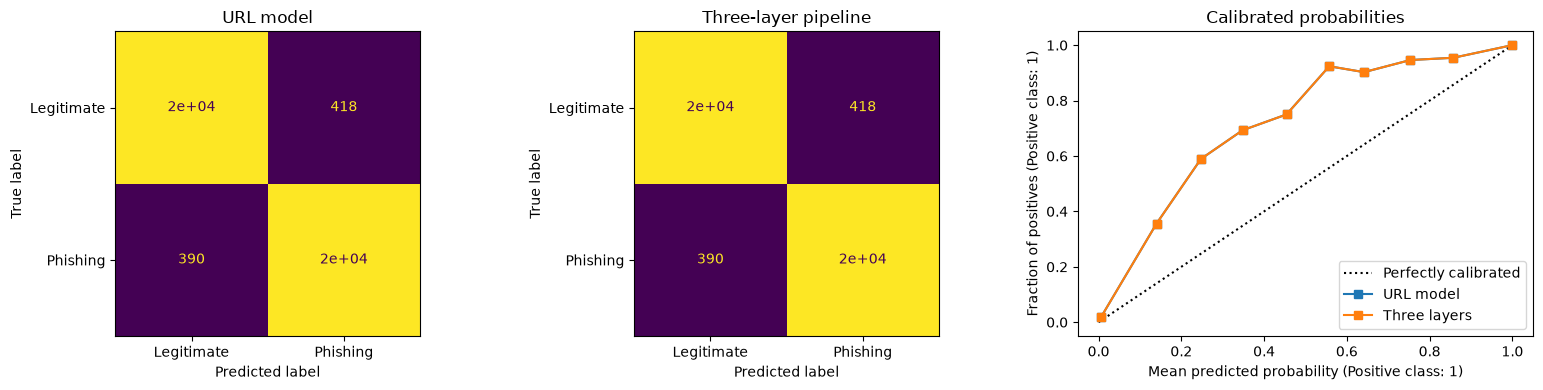

In [ ]:
print('URL-model recall-priority threshold:', CONFIG['model_decision_threshold'])
test_urls = data.iloc[test_idx]['URL'].tolist()
y_test = data.iloc[test_idx]['is_phishing'].to_numpy()
normalized_test_urls = [model_input_url(url) for url in test_urls]
model_scores = model.predict_proba(normalized_test_urls)[:, 1]
previous_bundle = joblib.load(PREVIOUS_ARTIFACT_PATH)
previous_threshold = float(previous_bundle.get('metadata', {}).get('default_decision_threshold', 0.5))
previous_scores = previous_bundle['model'].predict_proba([normalize_url(url)[0] for url in test_urls])[:, 1]
previous_metrics = score_metrics(y_test, previous_scores, previous_threshold)
decisions = [detector.explain(url) for url in test_urls]
pipeline_scores = np.array([decision['final_score'] for decision in decisions])
typo_only_test_rows = [detector.typo_only_features(url) for url in test_urls]
typo_only_test_features = np.vstack([row[0] for row in typo_only_test_rows])
typo_only_scores = typo_only_calibrator.predict_proba(typo_only_test_features)[:, 1]
typo_only_signals = [row[1] for row in typo_only_test_rows]
whitelist_only_test_features = np.vstack([detector.whitelist_only_features(url)[0] for url in test_urls])
whitelist_only_scores = whitelist_only_calibrator.predict_proba(whitelist_only_test_features)[:, 1]
model_predictions = model_scores >= CONFIG['model_decision_threshold']
pipeline_predictions = pipeline_scores >= CONFIG['pipeline_decision_threshold']
typo_only_predictions = typo_only_scores >= CONFIG['typo_only_decision_threshold']
whitelist_only_predictions = whitelist_only_scores >= CONFIG['whitelist_only_decision_threshold']
layer_counts = {'whitelist_signal': sum(d['layer_1_whitelisted'] for d in decisions),
                'typosquat_signal': sum(d['layer_2_typosquat'] for d in decisions),
                'model_scored': len(decisions)}
white_mask = np.array([d['layer_1_whitelisted'] for d in decisions])
typo_mask = np.array([d['layer_2_typosquat'] for d in decisions])
typo_only_mask = np.array([d['layer_2_typosquat'] for d in typo_only_signals])
layer_outcomes = pd.DataFrame({
    'urls': [int(white_mask.sum()), int(typo_mask.sum()), len(y_test)],
    'phishing': [int((white_mask & (y_test == 1)).sum()), int((typo_mask & (y_test == 1)).sum()), int((y_test == 1).sum())],
    'legitimate': [int((white_mask & (y_test == 0)).sum()), int((typo_mask & (y_test == 0)).sum()), int((y_test == 0).sum())]},
    index=['whitelist signal', 'typosquat signal', 'all model scores'])
typo_only_outcomes = {'matched_urls': int(typo_only_mask.sum()),
                      'matched_phishing': int((typo_only_mask & (y_test == 1)).sum()),
                      'matched_legitimate': int((typo_only_mask & (y_test == 0)).sum())}
pipeline_metrics = score_metrics(y_test, pipeline_scores, CONFIG['pipeline_decision_threshold'])
typo_only_metrics = score_metrics(y_test, typo_only_scores, CONFIG['typo_only_decision_threshold'])
model_metrics = score_metrics(y_test, model_scores, CONFIG['model_decision_threshold'])
paired_urls = data.iloc[test_idx].drop_duplicates(subset='URL').groupby(domains[test_idx], sort=True).first()['URL'].tolist()
paired_base_urls, paired_www_urls = [], []
for candidate_url in paired_urls:
    normalized, host, _ = normalize_url(candidate_url)
    parts = urlsplit(normalized)
    port = parts.port
    suffix = f':{port}' if port is not None else ''
    base_host = host[4:] if host.startswith('www.') else host
    base_netloc = base_host + suffix
    www_netloc = 'www.' + base_host + suffix
    paired_base_urls.append(urlunsplit((parts.scheme, base_netloc, parts.path, parts.query, parts.fragment)))
    paired_www_urls.append(urlunsplit((parts.scheme, www_netloc, parts.path, parts.query, parts.fragment)))
paired_base_scores = model.predict_proba([model_input_url(url) for url in paired_base_urls])[:, 1]
paired_www_scores = model.predict_proba([model_input_url(url) for url in paired_www_urls])[:, 1]
paired_www_audit = {'registrable_domains': len(paired_urls), 'pairs_with_equal_scores': int(np.isclose(paired_base_scores, paired_www_scores, rtol=0, atol=0).sum()),
                    'max_absolute_score_difference': float(np.max(np.abs(paired_base_scores - paired_www_scores))) if len(paired_urls) else 0.0}
assert paired_www_audit['pairs_with_equal_scores'] == paired_www_audit['registrable_domains']
subdomain_groups = []
for candidate_url, score, label in zip(test_urls, model_scores, y_test):
    _, host, domain = normalize_url(candidate_url)
    kind = 'www' if host.startswith('www.') else ('bare registrable domain' if host == domain else 'other subdomain')
    subdomain_groups.append({'subdomain_type': kind, 'model_score': float(score), 'is_phishing': int(label)})
subdomain_audit = pd.DataFrame(subdomain_groups).groupby('subdomain_type').agg(
    rows=('model_score', 'size'), mean_model_score=('model_score', 'mean'),
    phishing_rate=('is_phishing', 'mean')).reindex(['bare registrable domain', 'www', 'other subdomain']).dropna()
print('Paired bare/www counterfactual audit:', paired_www_audit)
display(subdomain_audit.round(4))
assert model_input_url('https://login.example.com/path') != model_input_url('https://example.com/path')
whitelist_only_metrics = score_metrics(y_test, whitelist_only_scores, CONFIG['whitelist_only_decision_threshold'])
display(pd.DataFrame({name: {key: values[key] for key in ('precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'brier')}
                      for name, values in {'url_model': model_metrics, 'three_layer': pipeline_metrics}.items()}).T.round(4))
comparison = pd.DataFrame({name: {'threshold': threshold,
    'false_positives': values['confusion_matrix'][0][1], 'false_negatives': values['confusion_matrix'][1][0],
    'precision': values['precision'], 'recall': values['recall']} for name, threshold, values in
    [('url_model', CONFIG['model_decision_threshold'], model_metrics), ('url_plus_typo', CONFIG['typo_only_decision_threshold'], typo_only_metrics),
     ('url_plus_whitelist', CONFIG['whitelist_only_decision_threshold'], whitelist_only_metrics),
     ('three_layer', CONFIG['pipeline_decision_threshold'], pipeline_metrics)]}).T
comparison.loc['previous_url_model'] = {'threshold': previous_threshold,
    'false_positives': previous_metrics['confusion_matrix'][0][1], 'false_negatives': previous_metrics['confusion_matrix'][1][0],
    'precision': previous_metrics['precision'], 'recall': previous_metrics['recall']}
display(comparison.round(4))
display(pd.DataFrame({'previous_url_model': {key: previous_metrics[key] for key in ('precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'brier')},
                      'www_normalized_candidate': {key: model_metrics[key] for key in ('precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'brier')}}).T.round(4))
print('Layer signal counts on test set:', layer_counts)
print('Validation-selected thresholds:', {'url_model': CONFIG['model_decision_threshold'], 'three_layer': CONFIG['pipeline_decision_threshold']})
display(layer_outcomes)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay(np.array(model_metrics['confusion_matrix']), display_labels=['Legitimate', 'Phishing']).plot(ax=axes[0], colorbar=False)
axes[0].set_title('URL model')
ConfusionMatrixDisplay(np.array(pipeline_metrics['confusion_matrix']), display_labels=['Legitimate', 'Phishing']).plot(ax=axes[1], colorbar=False)
axes[1].set_title('Three-layer pipeline')
CalibrationDisplay.from_predictions(y_test, model_scores, n_bins=10, ax=axes[2], name='URL model')
CalibrationDisplay.from_predictions(y_test, pipeline_scores, n_bins=10, ax=axes[2], name='Three layers')
axes[2].set_title('Calibrated probabilities')
plt.tight_layout()
plt.show()


In [ ]:
length_bands = pd.cut(pd.Series(test_urls).str.len(), bins=[0, 30, 60, 100, 250, np.inf],
    labels=['1-30', '31-60', '61-100', '101-250', '251+'])
rows = []
for band in length_bands.cat.categories:
    mask = (length_bands == band).to_numpy()
    if not mask.any():
        continue
    predicted = pipeline_scores[mask] >= CONFIG['pipeline_decision_threshold']
    actual = y_test[mask]
    tp = int((predicted & (actual == 1)).sum())
    fp = int((predicted & (actual == 0)).sum())
    fn = int((~predicted & (actual == 1)).sum())
    rows.append({'url_length': band, 'rows': int(mask.sum()), 'phishing_rate': float(actual.mean()),
                 'predicted_phishing_rate': float(predicted.mean()),
                 'precision': tp / (tp + fp) if tp + fp else np.nan,
                 'recall': tp / (tp + fn) if tp + fn else np.nan})
length_audit = pd.DataFrame(rows)
display(length_audit.round(4))
print('Source limitation: legitimate URLs end at length 58; longer bands contain phishing examples only.')


,url_length,rows,phishing_rate,predicted_phishing_rate,precision,recall
0,1-30,22647,0.3267,0.3242,0.9672,0.9600
1,31-60,15541,0.6875,0.6929,0.9836,0.9912
2,61-100,1320,1.0000,1.0000,1.0000,1.0000
3,101-250,529,1.0000,1.0000,1.0000,1.0000
4,251+,172,1.0000,1.0000,1.0000,1.0000


Source limitation: legitimate URLs end at length 58; longer bands contain phishing examples only.


## Saved artifact

In [ ]:
metadata = {'default_prediction_mode': 'url_model', 'default_decision_threshold': CONFIG['model_decision_threshold'],
            'model_max_validation_fpr': MODEL_MAX_VALIDATION_FPR,
            'source_sha256': source_sha256(SOURCE_PATH),
            'cleaned_sha256': source_sha256(DATASET_PATH),
            'domain_reference': reference_metadata,
            'test_rows': len(test_idx), 'split_report': split_report.to_dict('records'),
            'model_metrics': model_metrics, 'pipeline_metrics': pipeline_metrics,
            'typo_only_metrics': typo_only_metrics, 'whitelist_only_metrics': whitelist_only_metrics,
            'model_decision_threshold': CONFIG['model_decision_threshold'],
            'pipeline_decision_threshold': CONFIG['pipeline_decision_threshold'],
            'typo_only_decision_threshold': CONFIG['typo_only_decision_threshold'],
            'whitelist_only_decision_threshold': CONFIG['whitelist_only_decision_threshold'],
            'validation_model_recall_target': float(target_recall),
            'validation_pipeline_recall': float(threshold_recall),
            'validation_typo_only_recall': float(typo_threshold_recall),
            'validation_model_recall': float(model_threshold_recall),
            'validation_whitelist_only_recall': float(whitelist_threshold_recall),
            'layer_feature_names': ['model_score', 'whitelist_match', 'typosquat_match', 'typo_similarity'],
            'typo_only_feature_names': ['model_score', 'typosquat_match', 'typo_similarity'],
            'whitelist_only_feature_names': ['model_score', 'whitelist_match'],
            'layer_counts': dict(layer_counts), 'layer_outcomes': layer_outcomes.to_dict('index'),
            'typo_only_outcomes': typo_only_outcomes, 'comparison': comparison.to_dict('index'),
            'length_audit': length_audit.to_dict('records'),
            'model_input_policy': 'Remove only leading www. from character-model input; preserve other subdomains and original normalized URL for reporting/domain signals.',
            'paired_www_audit': paired_www_audit, 'subdomain_audit': subdomain_audit.reset_index().to_dict('records'),
            'previous_model_metrics_same_test': previous_metrics, 'previous_model_threshold': previous_threshold,
            'augmentation': {'enabled': CONFIG['augment_subdomain_erasure'], 'method': 'training-only phishing subdomain erasure to registrable domain',
                            'synthetic_example_weight': SUBDOMAIN_AUGMENTATION_WEIGHT, 'class_total_weights_normalized': True}}
save_bundle(ARTIFACT_PATH, detector, metadata)
print(f'Saved {ARTIFACT_PATH}')


Saved artifacts\phishing_detector_www_no_erasure_candidate.joblib


## Inference
The character model removes only a leading `www.` from its input. The original normalized URL is still used for reporting and domain signals, and other subdomains remain part of the model input. Phishing subdomain erasure is disabled: removing `docs.` from a phishing URL can wrongly teach the model that `google.com` itself is phishing. The paired audit checks `www` invariance and reports actual test scores for bare hosts, `www`, and other subdomains. `www` normalization does not indicate safety. Candidate output is written to `artifacts/phishing_detector_www_no_erasure_candidate.joblib`; compare its same-test metrics against the previous baseline before promoting it.

In [ ]:
reload_smoke_url = 'https://google.com/'
normalized_reload_url = model_input_url(reload_smoke_url)
model_probability_before_reload = float(detector.model.predict_proba([normalized_reload_url])[0, 1])
probability_before_reload = detector.predict_proba(reload_smoke_url)
typo_probability_before_reload = detector.predict_typo_only_probability(reload_smoke_url)
whitelist_probability_before_reload = detector.predict_whitelist_only_probability(reload_smoke_url)
detector, artifact_metadata = load_bundle(ARTIFACT_PATH)
assert artifact_metadata.get('default_prediction_mode') == 'url_model', 'Load the restored URL baseline artifact; this is an older pipeline bundle.'
model_probability_after_reload = float(detector.model.predict_proba([normalized_reload_url])[0, 1])
probability_after_reload = detector.predict_proba(reload_smoke_url)
typo_probability_after_reload = detector.predict_typo_only_probability(reload_smoke_url)
whitelist_probability_after_reload = detector.predict_whitelist_only_probability(reload_smoke_url)
assert np.isclose(model_probability_before_reload, model_probability_after_reload), 'Saved URL model changed its prediction.'
assert np.isclose(probability_before_reload, probability_after_reload), 'Saved bundle changed the prediction.'
assert np.isclose(typo_probability_before_reload, typo_probability_after_reload), 'Saved typo-only bundle changed the prediction.'
assert np.isclose(whitelist_probability_before_reload, whitelist_probability_after_reload), 'Saved whitelist-only bundle changed the prediction.'
assert 0.0 < detector.predict_proba('https://www.google.com/') < 1.0
assert 0.0 < detector.predict_proba(reload_smoke_url) < 1.0
assert detector.config['typo_top_n'] == TYPO_TOP_N, 'TYPO_TOP_N differs from the calibrated artifact; rerun training and calibration.'

def predict_phishing_probability(url: str) -> float:
    model_input = model_input_url(url)
    return float(detector.model.predict_proba([model_input])[0, 1])

def explain_phishing_prediction(url: str) -> dict:
    probability = predict_phishing_probability(url)
    return {'layer': 'url_model', 'model_score': probability, 'final_score': probability,
            'decision_threshold': float(detector.config['model_decision_threshold']),
            'reason': 'Recall-priority URL model operating point with a configured validation false-positive cap.'}

def explain_typo_only_prediction(url: str) -> dict:
    return detector.explain_typo_only(url)

assert predict_phishing_probability(reload_smoke_url) == model_probability_after_reload
assert explain_phishing_prediction(reload_smoke_url)['decision_threshold'] == detector.config['model_decision_threshold']
print(predict_phishing_probability('https://www.googl3.com/'))
print(explain_phishing_prediction('https://www.googlle.com/'))

# Quick inference: edit url, then run this cell to display the normalized URL and risk score.
url = 'https://labs.hackthebox.com'
normalized_url = normalize_url(url)[0]
pipeline_result = detector.explain(url)
risk_score = pipeline_result['final_score']
print(f'URL: {normalized_url}')
print(f'Risk score: {risk_score:.2%}')
print(f'Verdict: {pipeline_result["prediction"]}')
if pipeline_result['typosquat_warning']:
    print(f'Lookalike match: {pipeline_result["matched_domain"]} ({pipeline_result["similarity"]:.1%} similar)')


0.021984245319289875
{'layer': 'url_model', 'model_score': 0.01080837845093438, 'final_score': 0.01080837845093438, 'decision_threshold': 0.09177940217236609, 'reason': 'Recall-priority URL model operating point with a configured validation false-positive cap.'}
URL: https://labs.hackthebox.com/
Risk score: 0.23%
Verdict: LEGITIMATE
